# 03 可视化复现与交互大屏

**本笔记本作用**：完成 2.3 的全部可视化要求，对应论文第 5 章。

- **模板复现 14 张**（fig01–fig14）：对照《Excel数据可视化——从图表到大屏》第二章 30 种模板，
  复刻图表类型、布局、配色、标签与图例样式（要求 ≥10 种）
- **业务模型图 10 张**（fig15–fig24）：与第 3 章 7 类模型一一对应（要求 ≥6 张）
- **交互式大屏 1 个**：暗色主题，5 KPI + 8 图表 + 1 明细表 + 3 筛选器，支持联动与下钻

> 全部图表由 Python（Matplotlib / Seaborn / ECharts）生成，**未使用 Tableau / Power BI / FineBI**，也未用 Excel 截图替代。

In [1]:
# ============================================================
# 运行环境：conda 环境 business_analysis | 内核 business_analysis
# 本单元格作用：把 scripts 目录加入路径，并提供按文件名加载脚本的工具函数
# ============================================================
import sys, pathlib, importlib.util

ROOT = pathlib.Path.cwd().parent          # 项目根目录（notebooks 的上一级）
sys.path.insert(0, str(ROOT / "scripts"))  # 让脚本里的 import common 生效

def load_step(module_name: str, filename: str):
    """按文件名加载 scripts 下的脚本（文件名以数字开头，不能直接 import）。"""
    p = ROOT / "scripts" / filename
    spec = importlib.util.spec_from_file_location(module_name, p)
    m = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(m)
    return m

print("项目根目录：", ROOT)

项目根目录： G:\ThinkPad\Documents\jupyter_wenjian\商业数据分析\数据分析大作业


## 0. 图表规范

- 中文字体：Microsoft YaHei（自动探测，负号不乱码）
- 分辨率：200 dpi（要求 ≥150）
- 命名：`figXX_主题.png`
- 每张图带数据来源脚注，标题 + 副标题说明“复刻了哪个模板、看什么信息”

In [2]:
import common
print("中文字体：", common.CN_FONT)
print("图表输出目录：", common.OUT_FIG)

中文字体： Microsoft YaHei
图表输出目录： G:\ThinkPad\Documents\jupyter_wenjian\商业数据分析\数据分析大作业\outputs\figures


## 1. 模板复现（14 张）

复刻清单与对应关系：

| 编号 | 模板 | 数据映射 |
| --- | --- | --- |
| fig01 | 渐变柱形图 | 2026 年月度销售额 |
| fig02 | 带均值柱形图 | 17 个子类销售额 vs 均值线 |
| fig03 | 渐变圆角柱形图 | 四大区 2026 销售额 |
| fig04 | 标注柱形图 | 月度销售额 + 同比引线标签 |
| fig05 | 层叠柱形图 | 年份 × 品类构成 |
| fig06 | 蝴蝶图 | 子类 2025 vs 2026 对称对比 |
| fig07 | 对比柱形图 | 大区两年并列 + 增速 |
| fig08 | 甘特图 | 配送方式履约周期 P10–P90 |
| fig09 | 平滑折线图 | 48 个月销售额趋势 |
| fig10 | 菱形走势图 | 季度销售额节点 |
| fig11 | 对比折线图 | 2025 vs 2026 月度双线 |
| fig12 | 单值圆环图 | 整体毛利率 |
| fig13 | 水球图 | 履约达标率 |
| fig14 | 南丁格尔玫瑰图 | 子类销售额结构 |

In [3]:
vis = load_step("step04", "04_visuals.py")
res = vis._load_analysis().run_all()
vis.run_templates(res["orders"])

[1/9] M1 同比环比 + 移动平均（48 个月）
  [√] 已保存结果表：t06_月度趋势_同比环比.csv
[2/9] M2 帕累托 / ABC 分类
  [√] 已保存结果表：t07_帕累托_ABC_子类.csv
  [√] 已保存结果表：t07_帕累托_ABC_客户.csv
[3/9] M3 RFM 八分类
  [√] 已保存结果表：t08a_RFM阈值.csv
  [√] 已保存结果表：t08_RFM客户明细.csv
  [√] 已保存结果表：t09_RFM八分类汇总.csv
      RFM 阈值：R=76 天，F=6 次，M=2,243 美元
[4/9] M4 K-Means 用户分群


  [√] 已保存结果表：t10a_KMeans轮廓系数.csv
  [√] 已保存结果表：t10_KMeans客群画像.csv
      K-Means 最优 K=3（轮廓系数 0.262）
[5/9] M5 同期群留存
  [√] 已保存结果表：t11_同期群留存矩阵.csv
  [√] 已保存结果表：t11b_平均留存曲线.csv
      同期群：12 个群，平均首月留存 11.7%
[6/9] M6 波士顿矩阵
  [√] 已保存结果表：t12_波士顿矩阵.csv
      BCG 分界线：份额 5.88%，整体增速 21.44%
[7/9] M7 时间序列预测（SARIMA vs Holt-Winters）


F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting p

F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(
F:\anaconda3\envs\business_analysis\lib\site-packages\statsmodels\tsa\statespace\sarimax.py:1022: EstimationWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  self._conditional_sum_squares(


... (15 outputs left out)

  [√] 已保存图表：fig09_平滑折线图.png


  [√] 已保存图表：fig10_菱形走势图.png


  [√] 已保存图表：fig11_对比折线图.png
  [√] 已保存图表：fig12_单值圆环图.png


  [√] 已保存图表：fig13_水球图.png
  [√] 已保存图表：fig14_玫瑰图.png


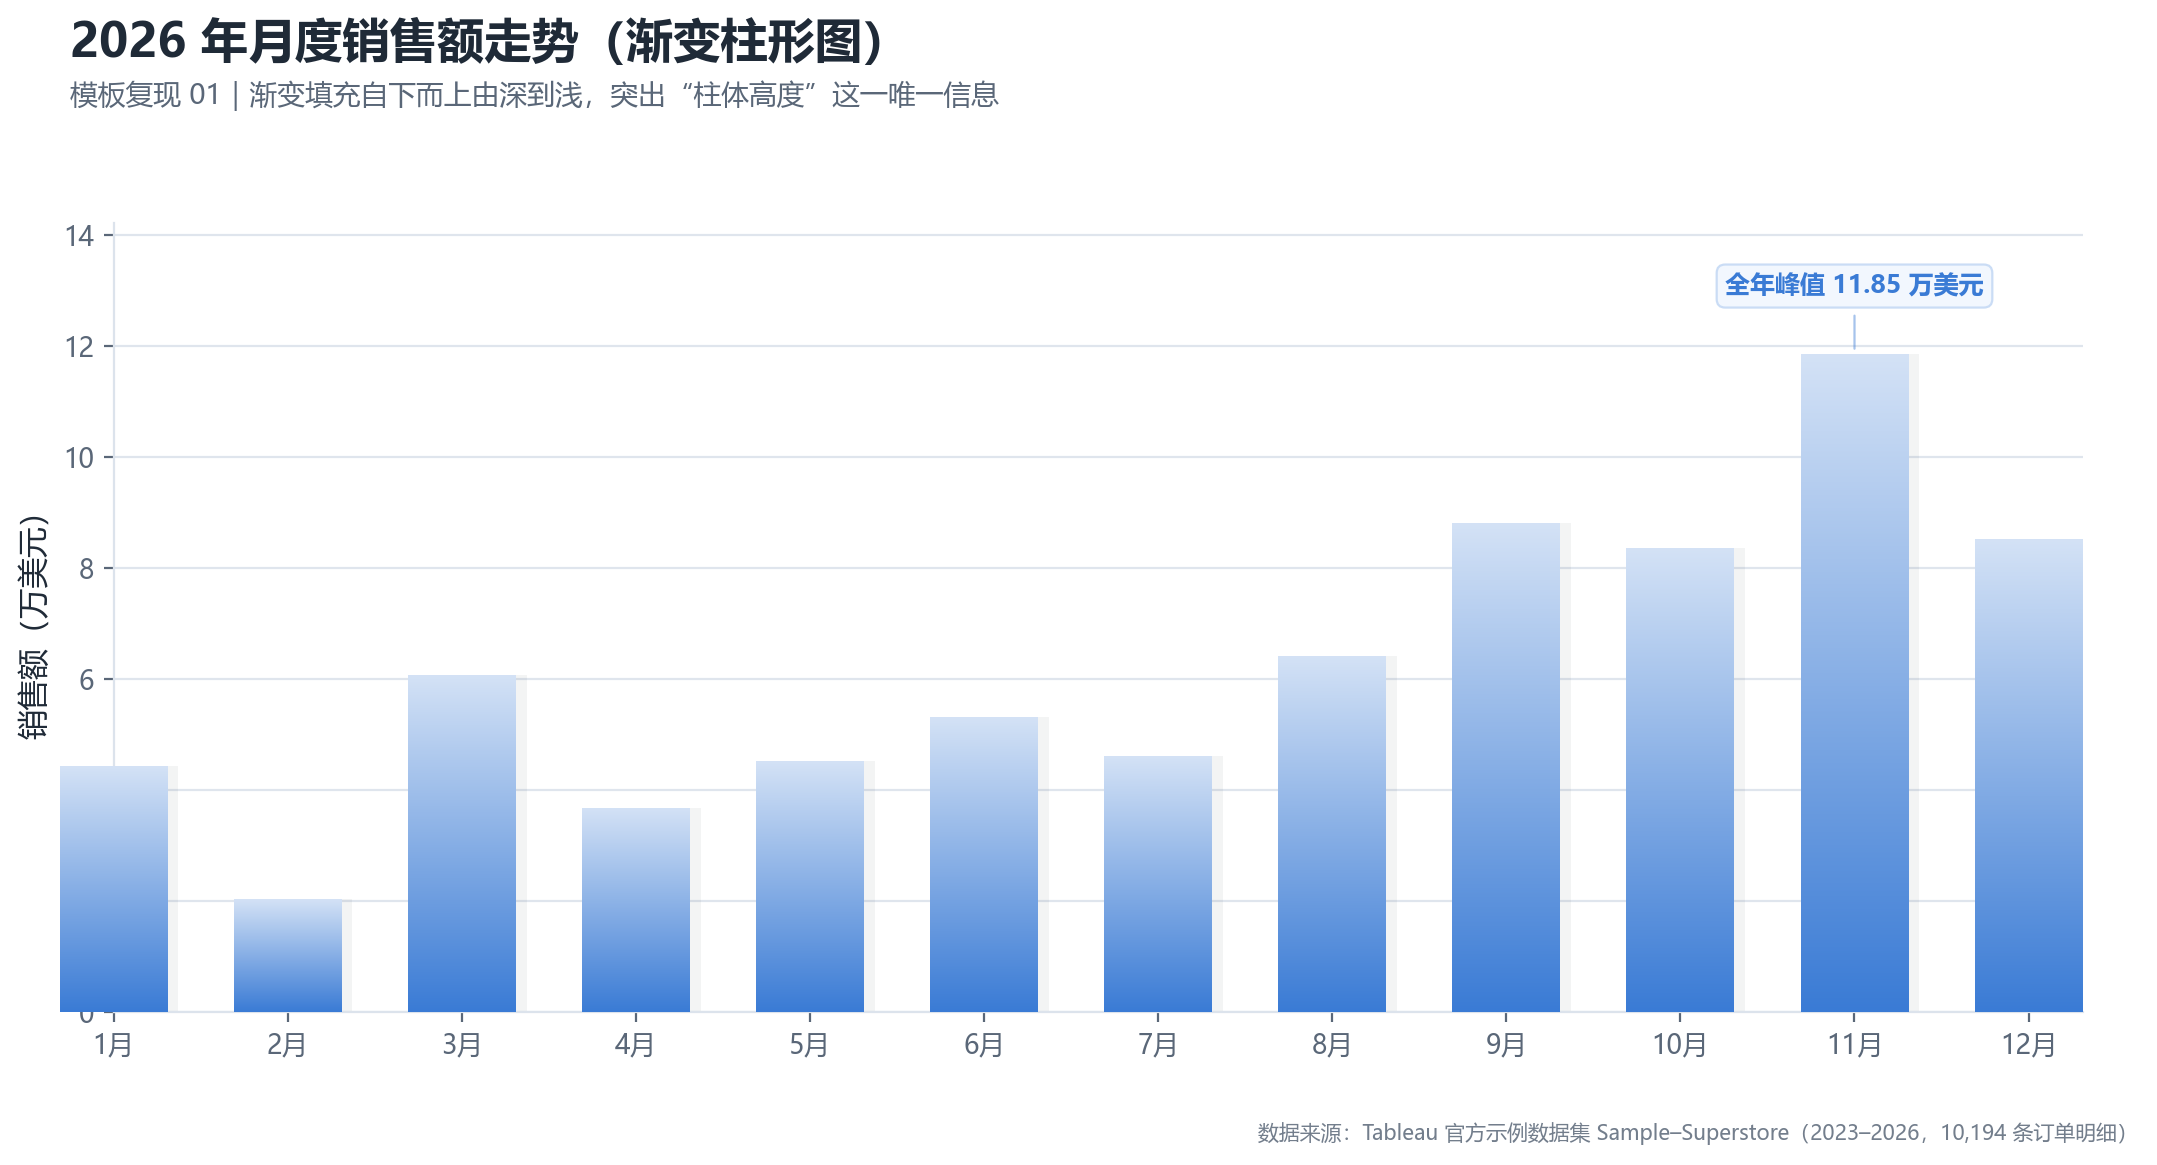

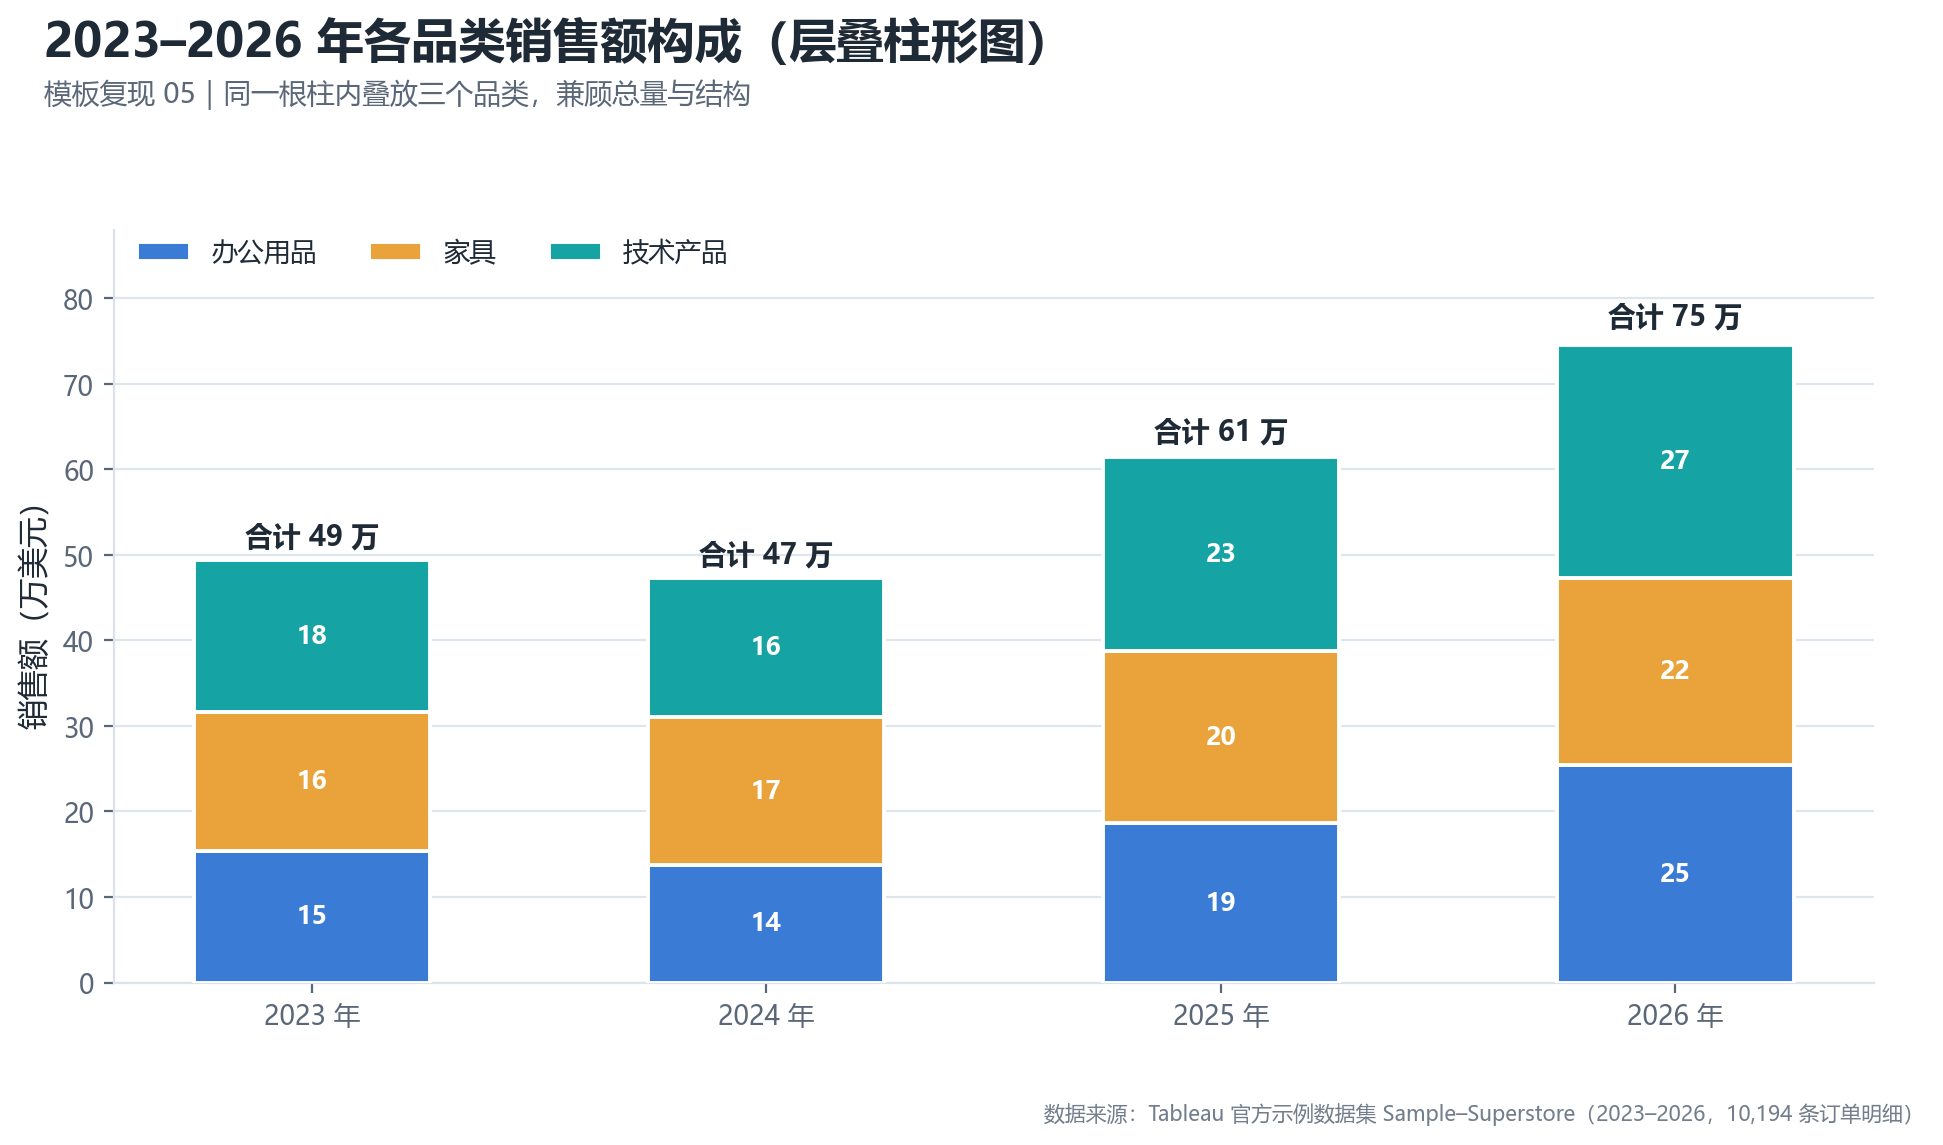

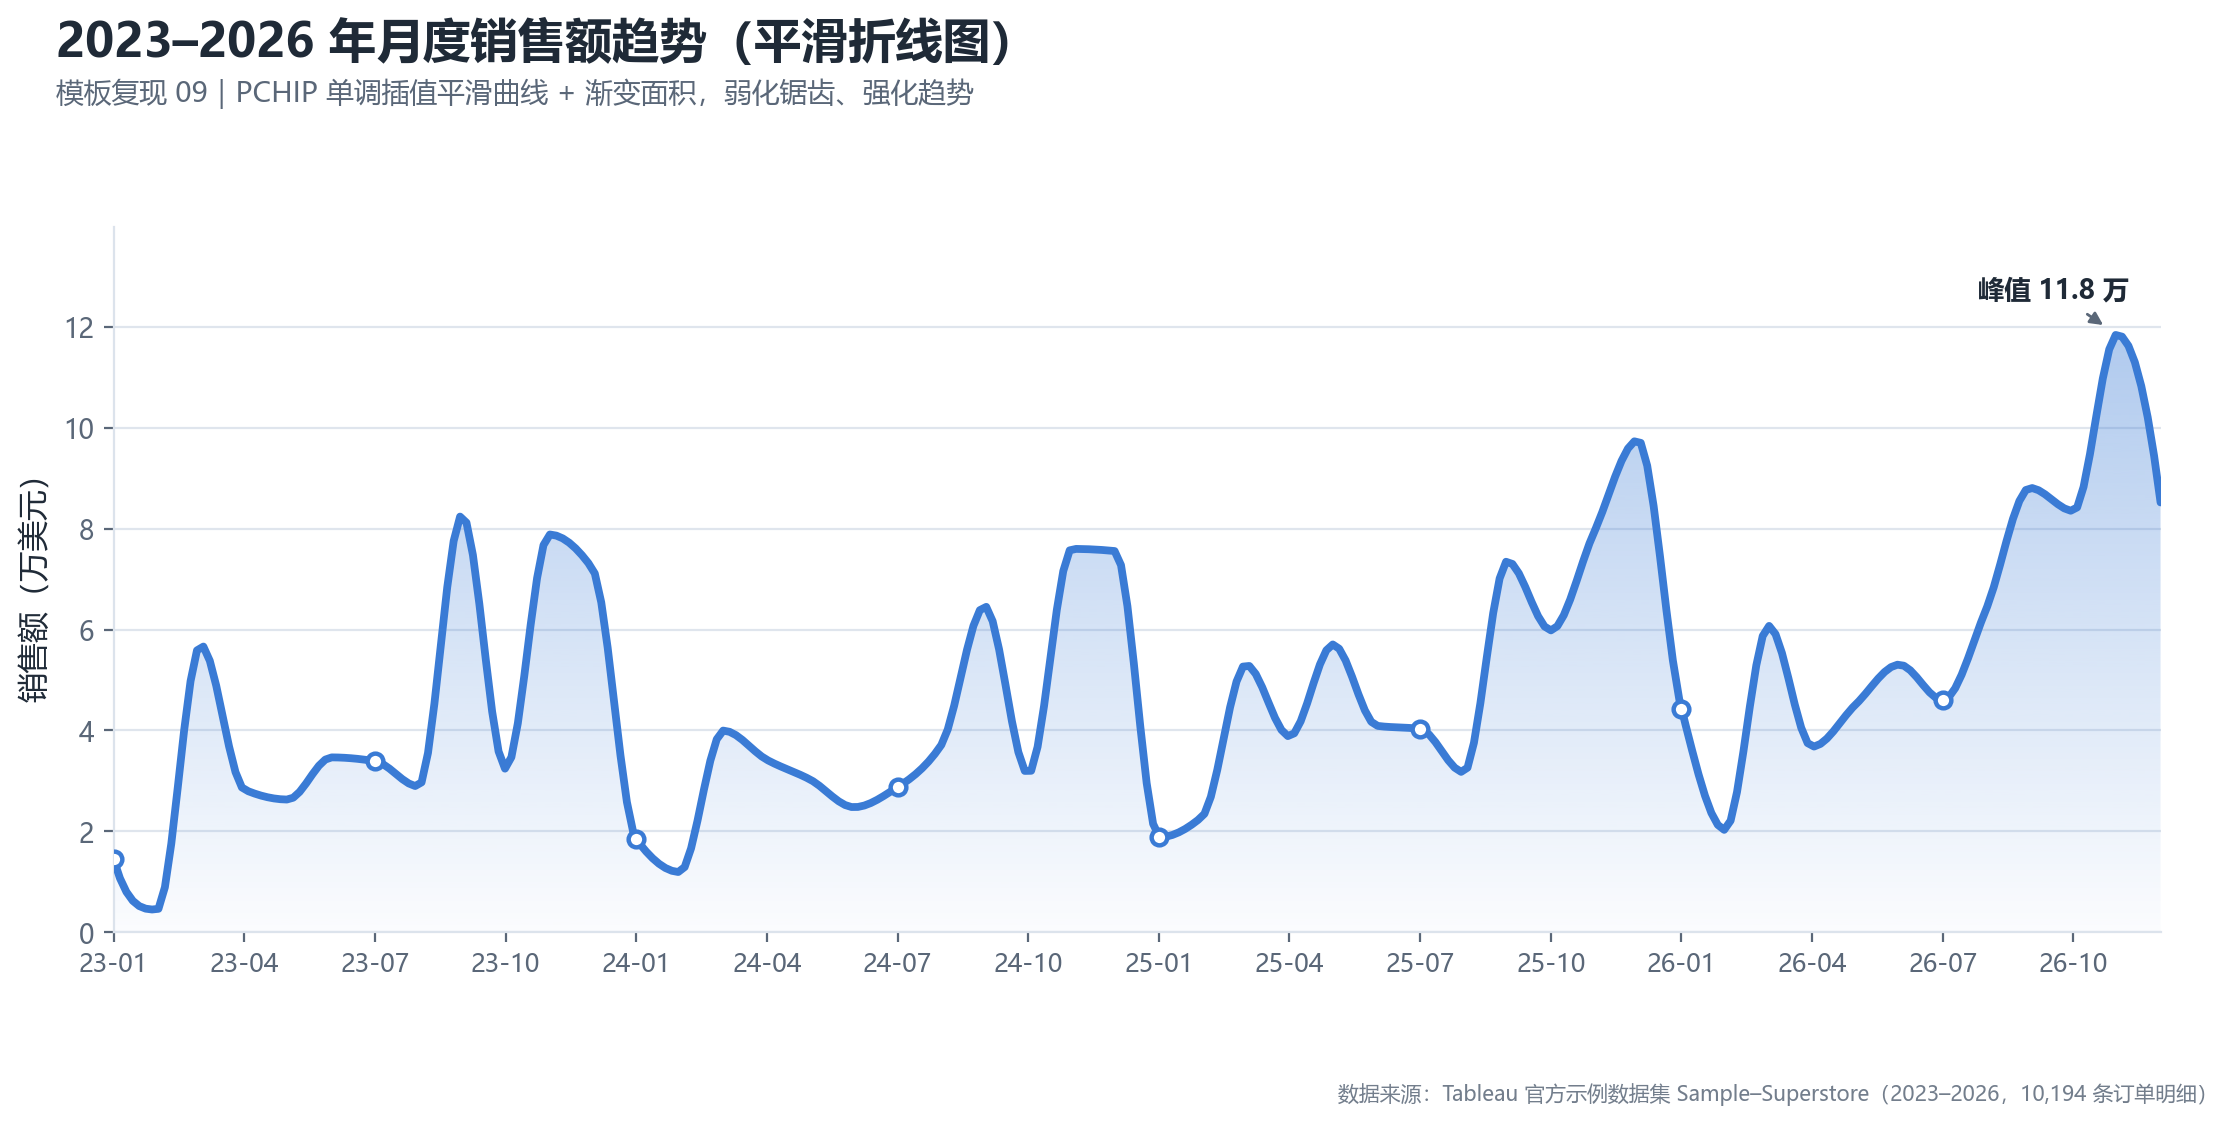

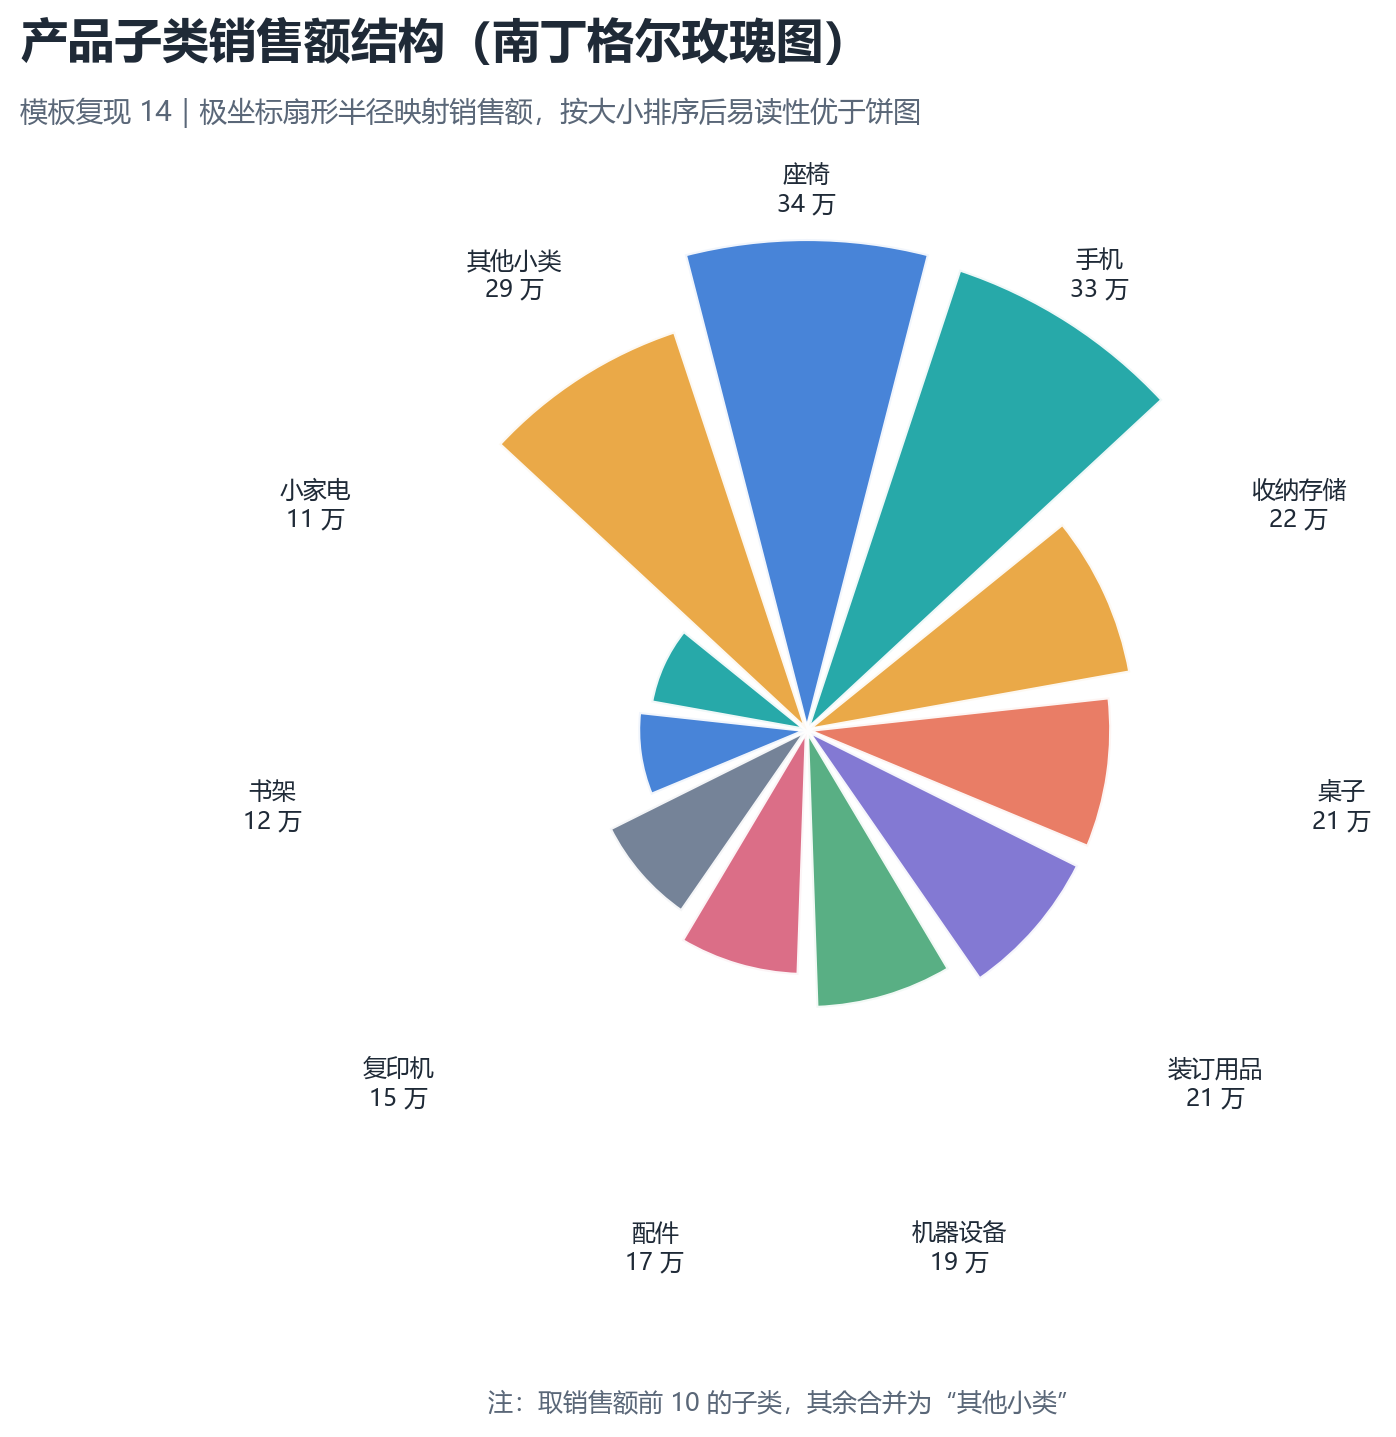

In [4]:
from IPython.display import Image, display
for f in ["fig01_渐变柱形图.png","fig05_层叠柱形图.png","fig09_平滑折线图.png","fig14_玫瑰图.png"]:
    display(Image(filename=str(ROOT/"outputs"/"figures"/f), width=760))

## 2. 业务模型图（10 张，与模型一一对应）

fig15 同比环比趋势（M1）→ fig16 帕累托（M2）→ fig17 RFM（M3）→ fig18 K-Means（M4）
→ fig19 同期群（M5）→ fig20 波士顿矩阵（M6）→ fig21 预测区间（M7）
→ fig22 关联规则（M8）→ fig23 漏斗（M9）→ fig24 折扣弹性（定价建议）

In [5]:
vis.run_business(res)

[B] 业务模型图：10 张


  [√] 已保存图表：fig15_月度趋势与同比.png


  [√] 已保存图表：fig16_帕累托ABC.png


  [√] 已保存图表：fig17_RFM八分类.png


  [√] 已保存图表：fig18_KMeans客群.png


  [√] 已保存图表：fig19_同期群留存.png


  [√] 已保存图表：fig20_波士顿矩阵.png


  [√] 已保存图表：fig21_预测置信区间.png


  [√] 已保存图表：fig22_关联规则.png
  [√] 已保存图表：fig23_履约漏斗.png


  [√] 已保存图表：fig24_折扣毛利弹性.png


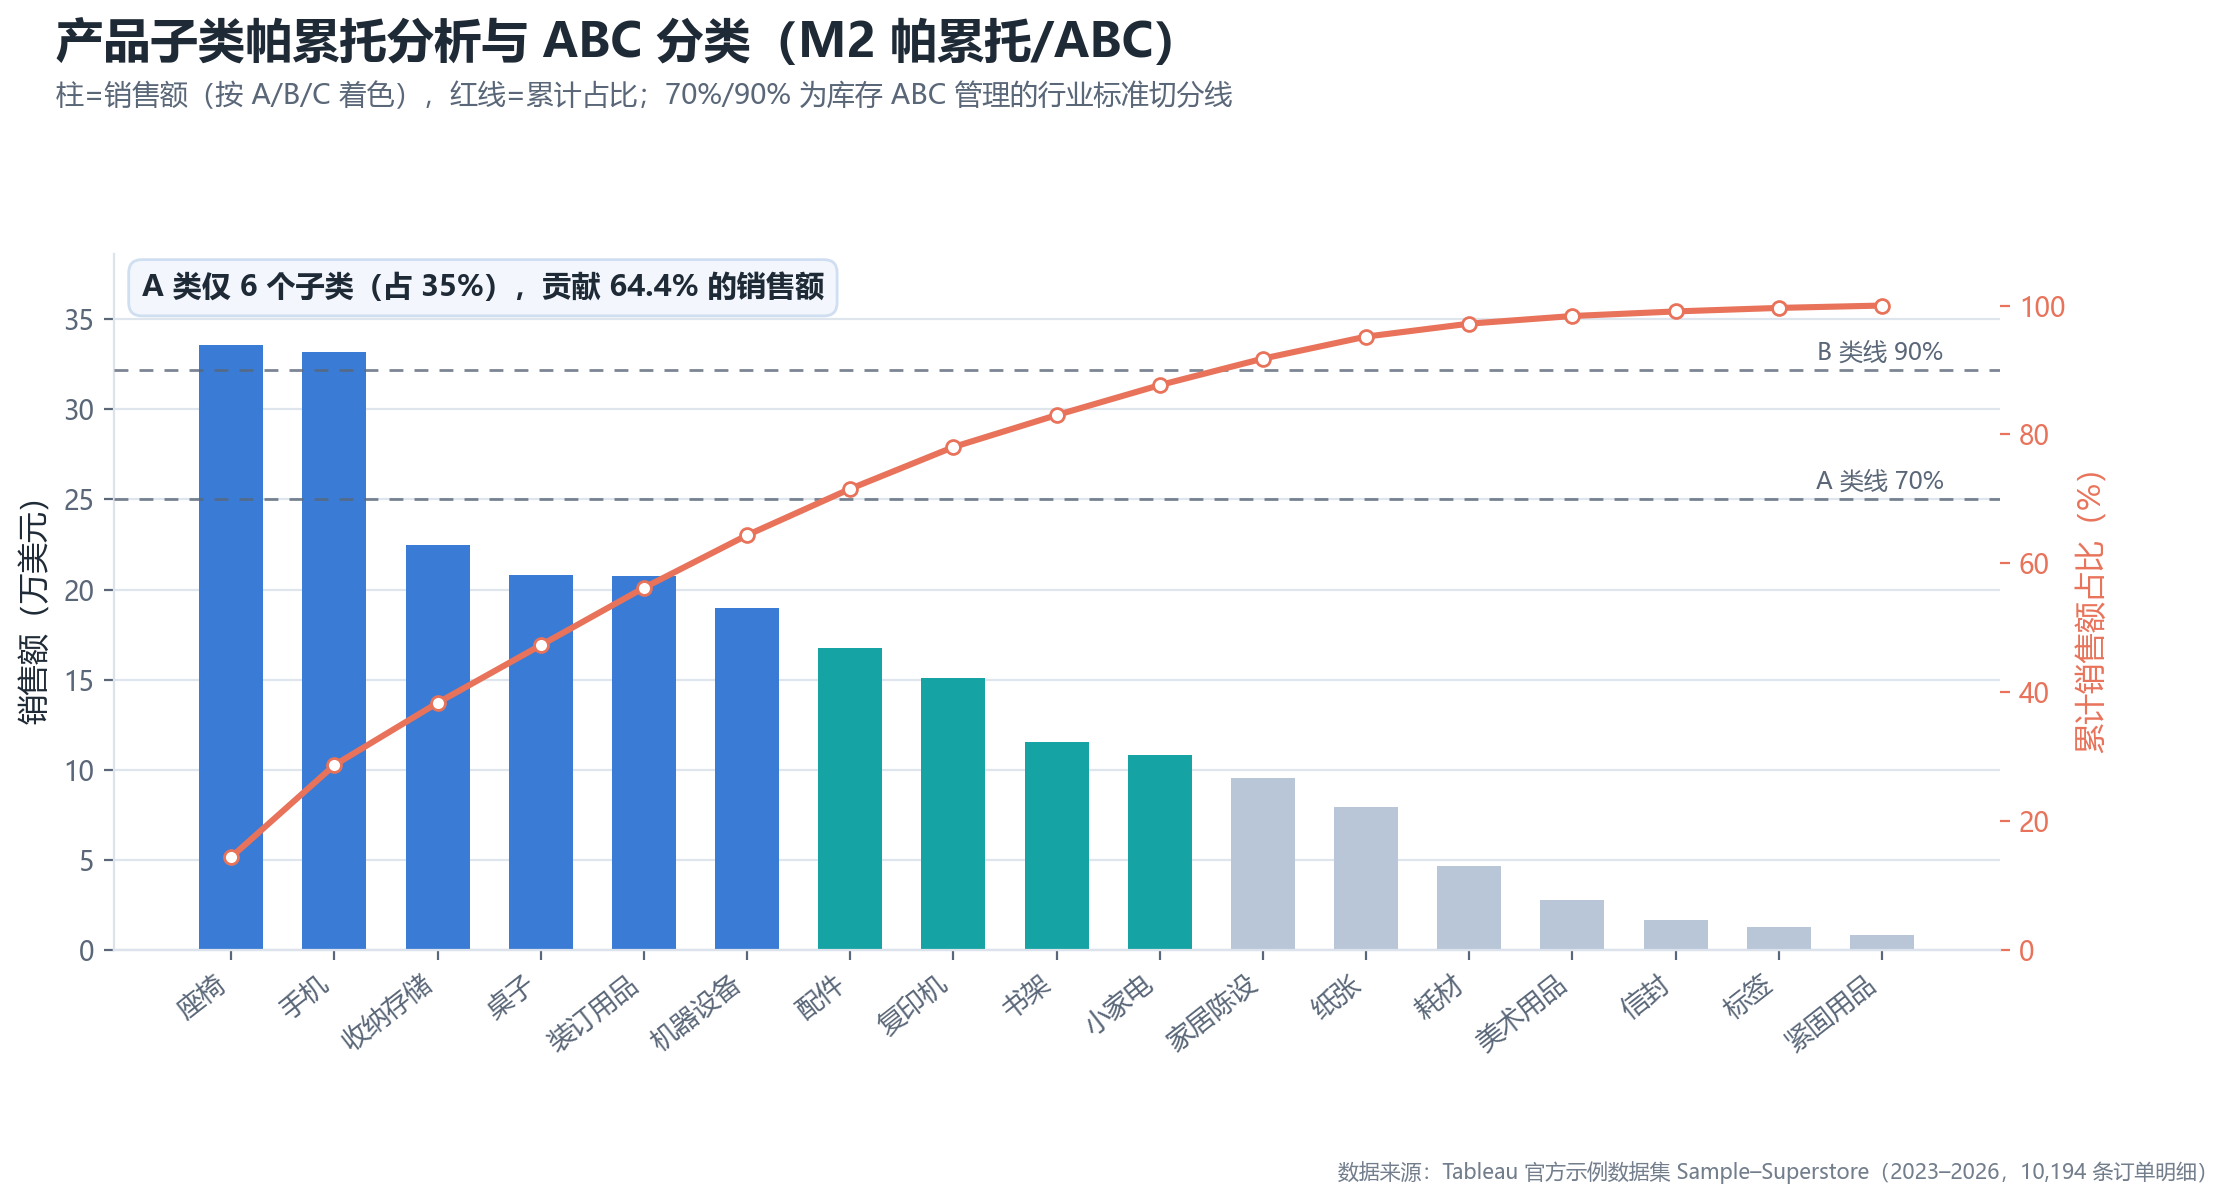

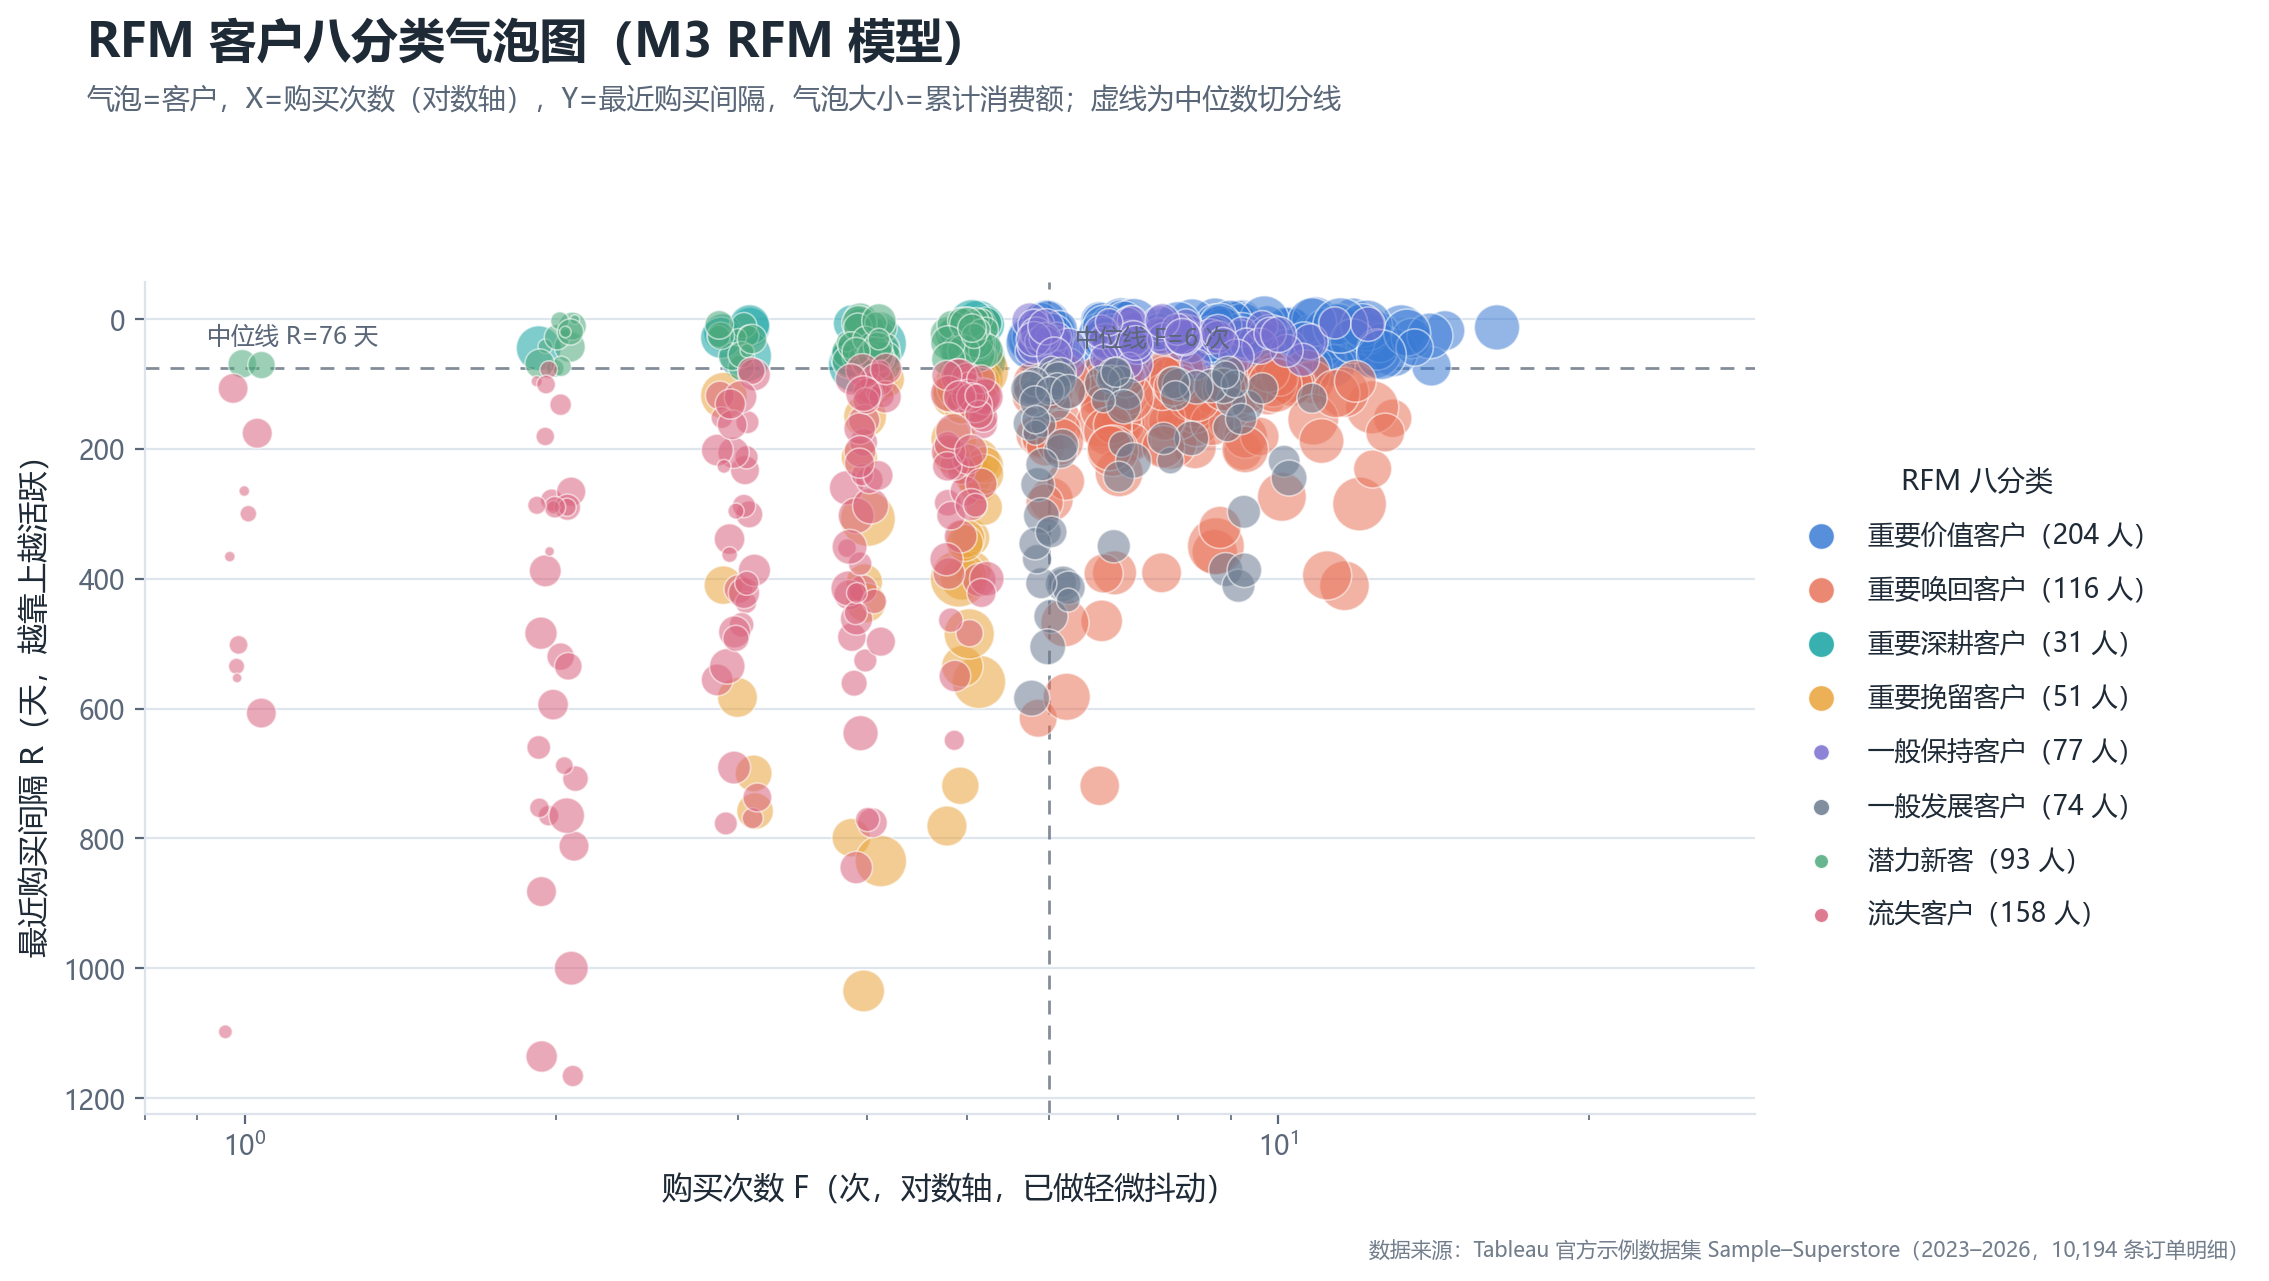

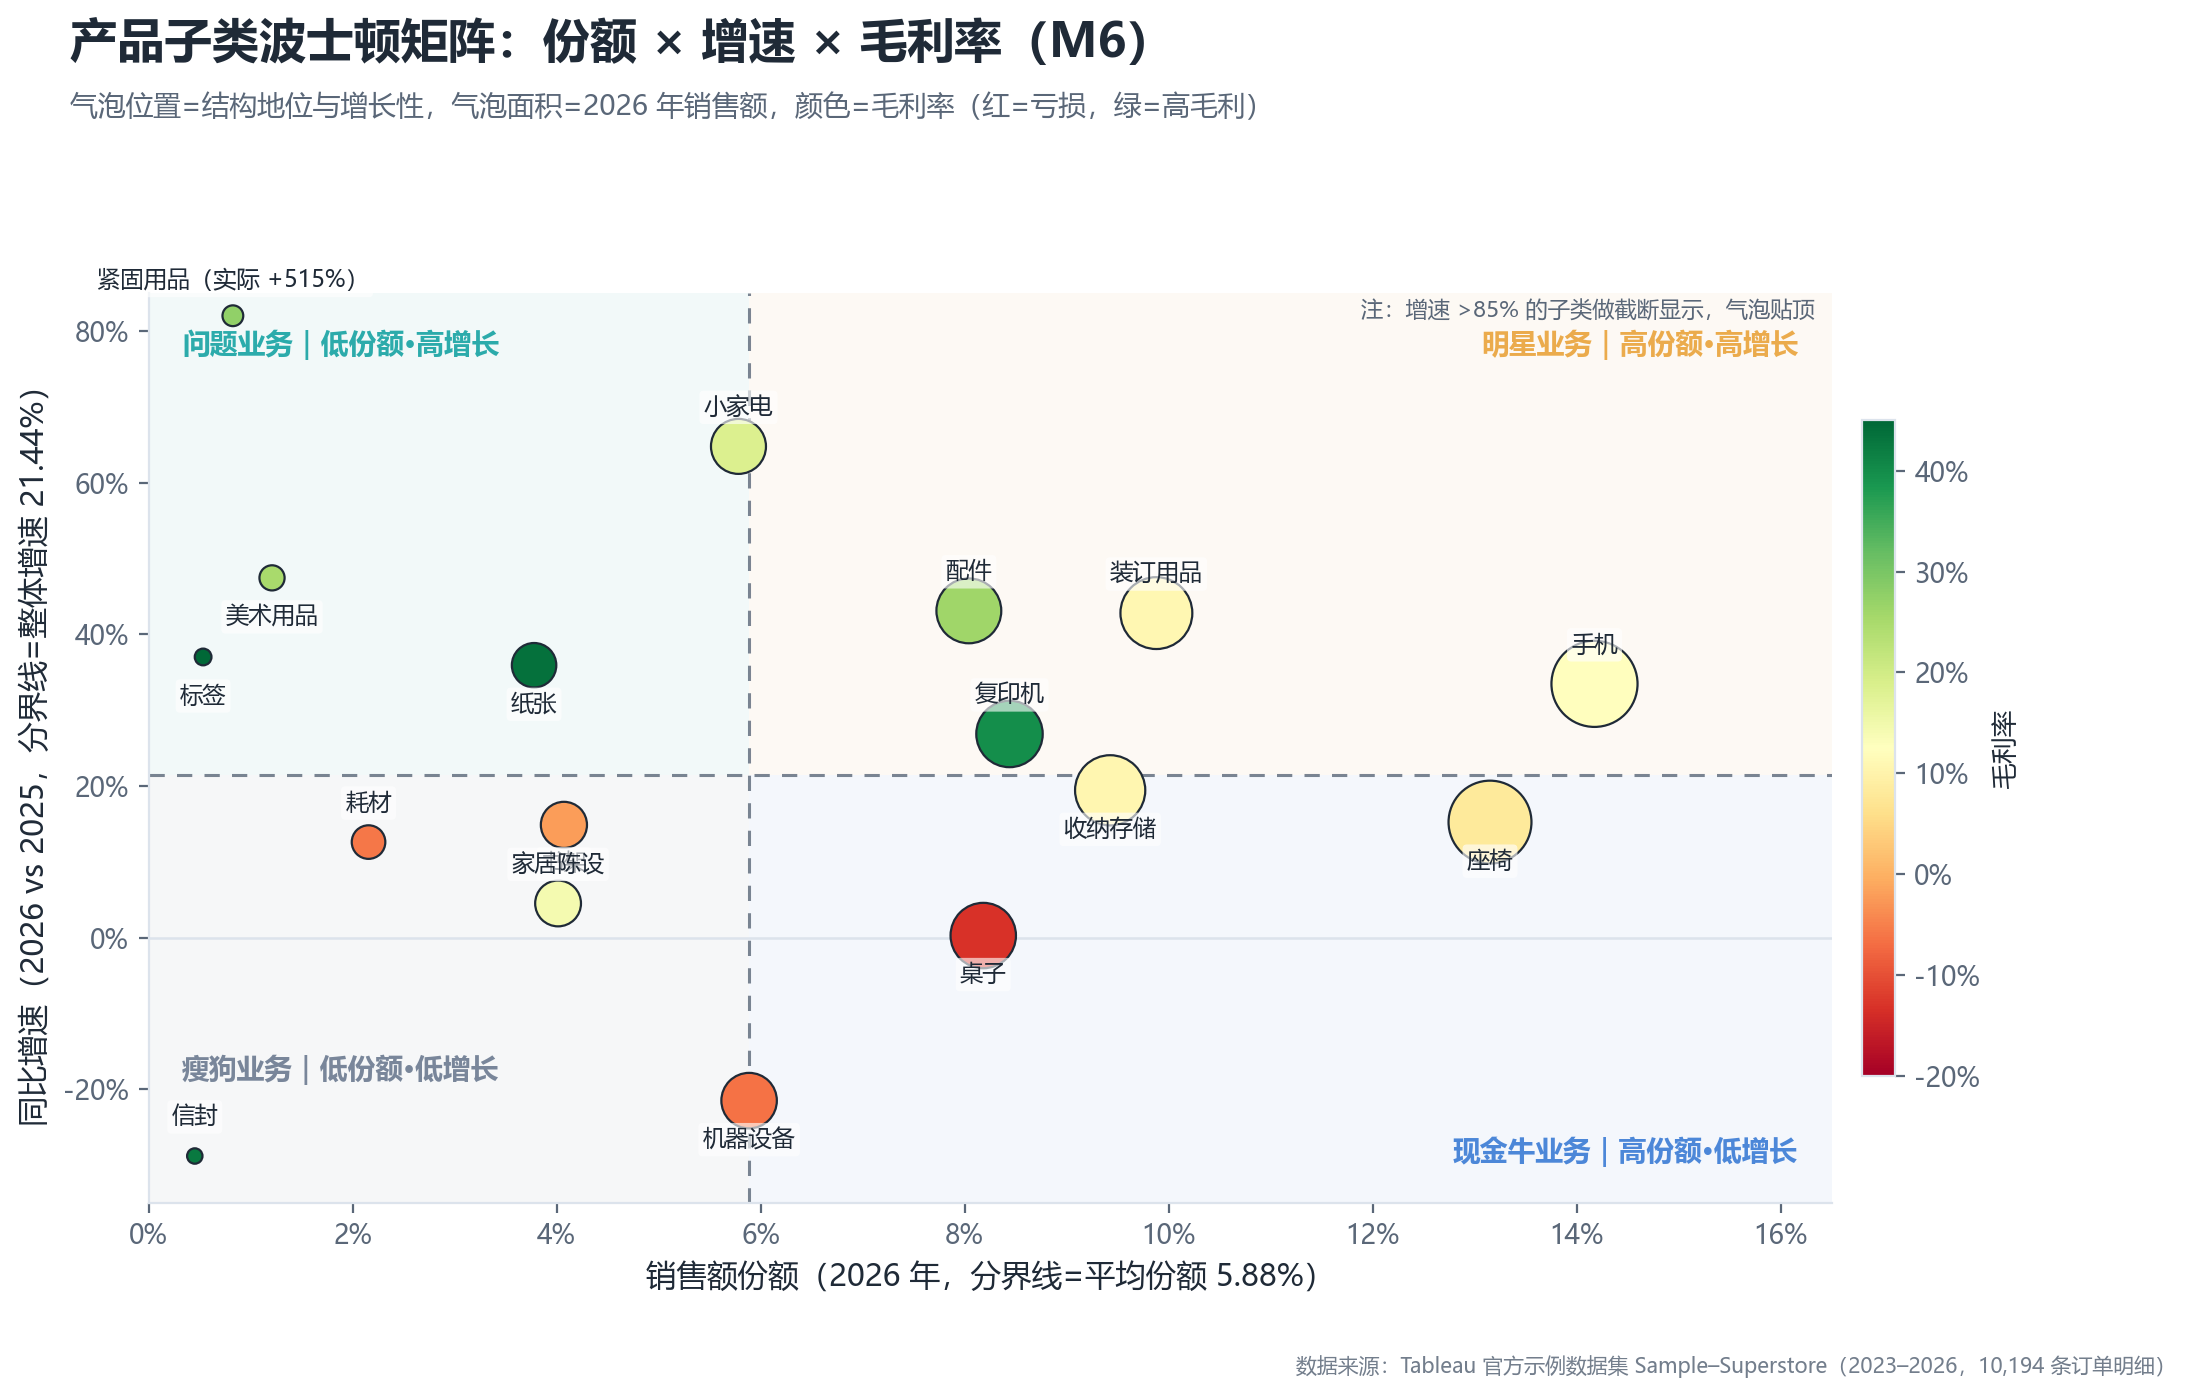

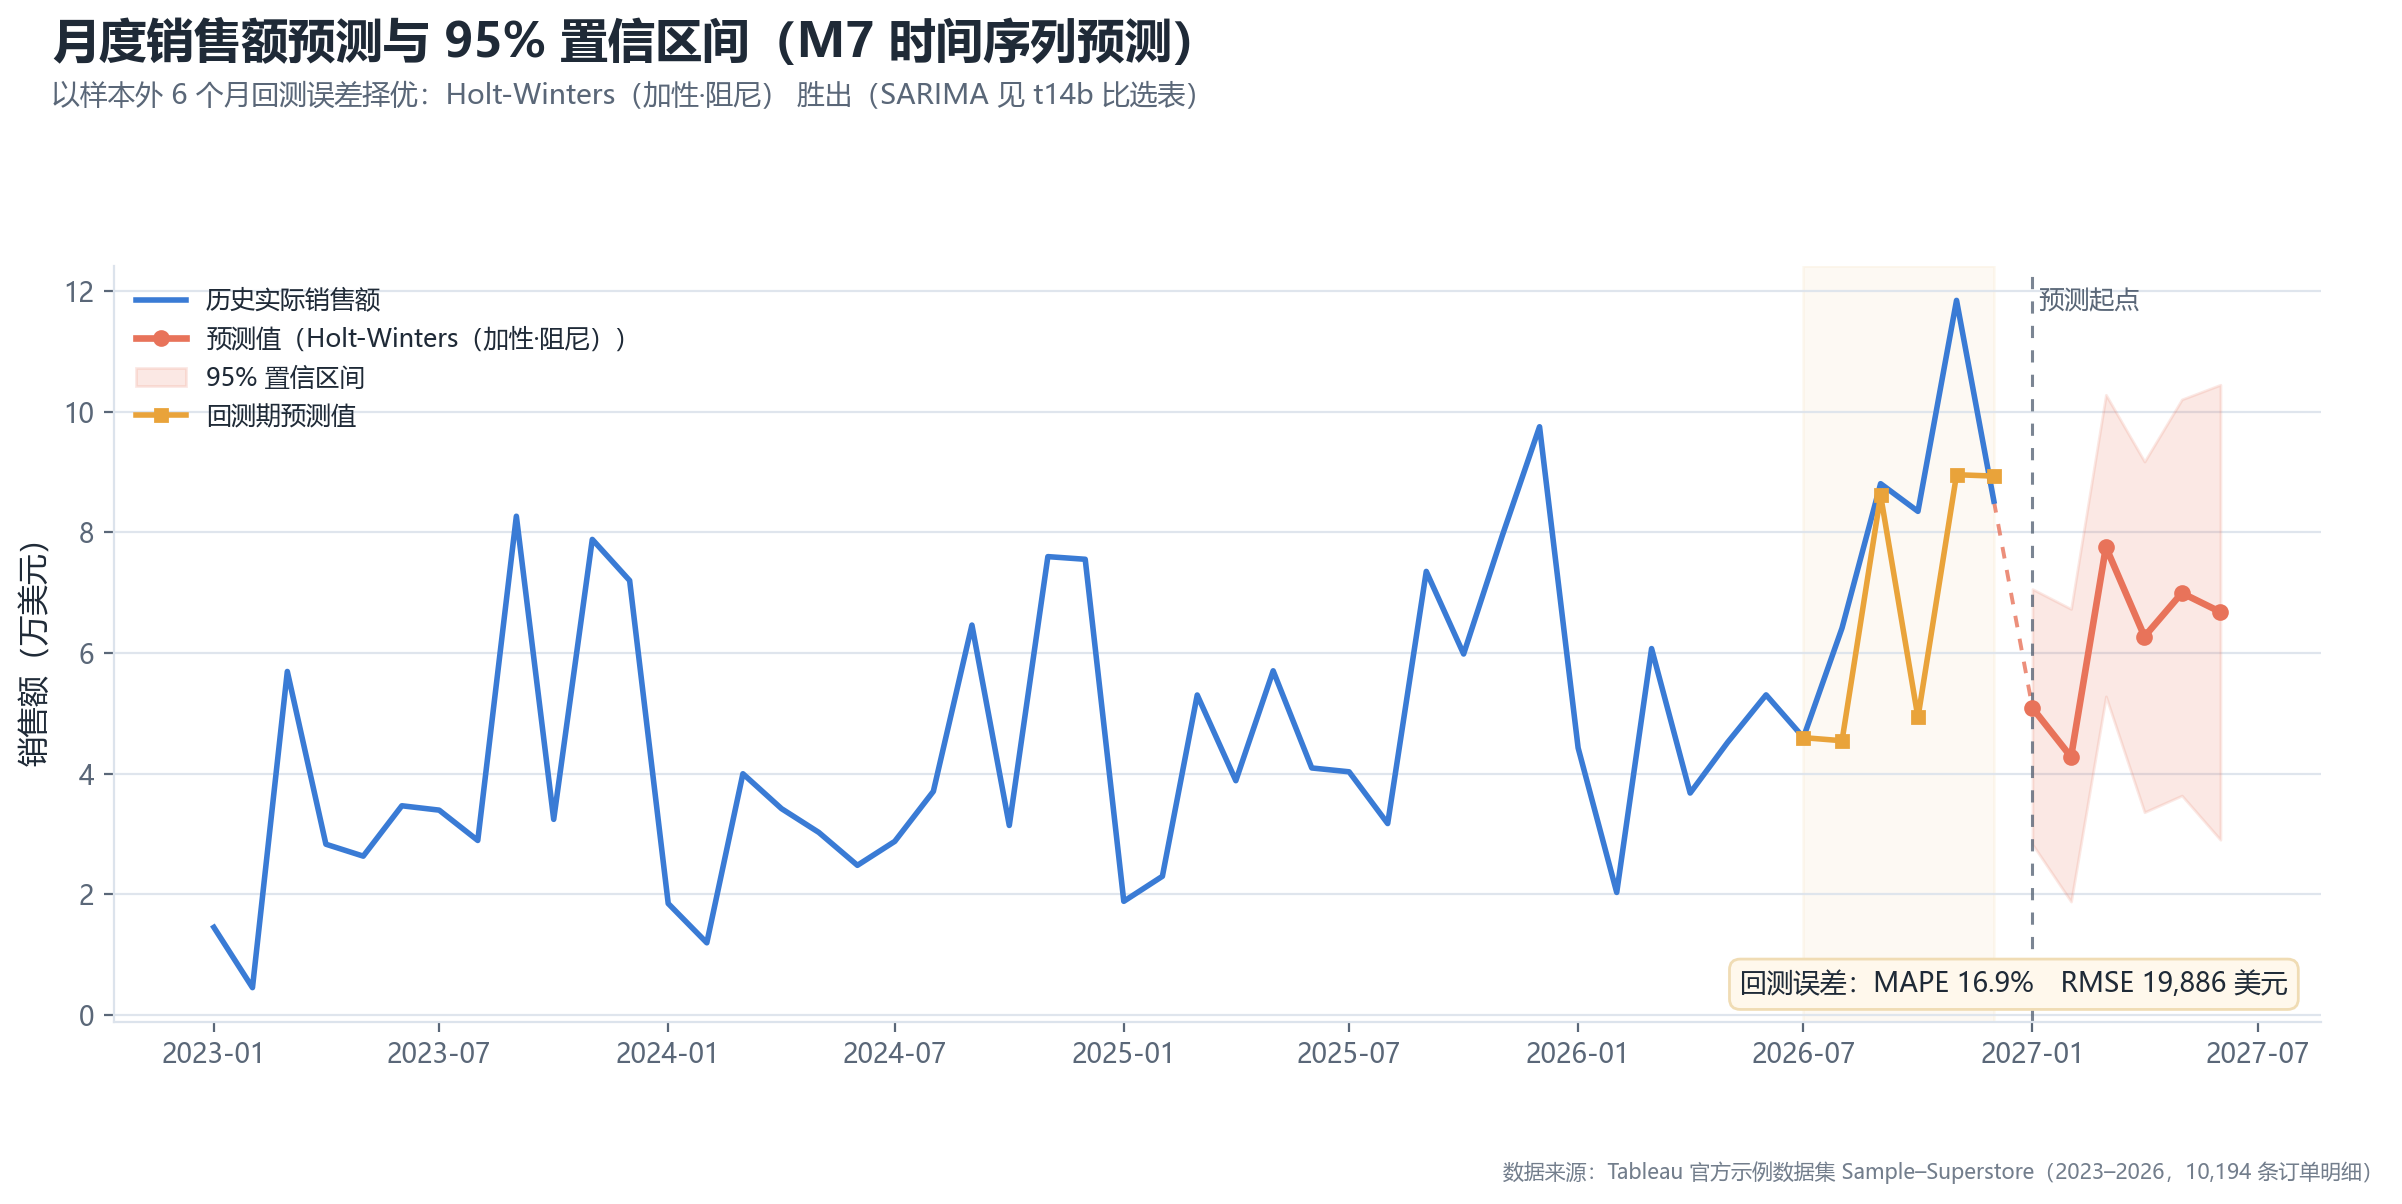

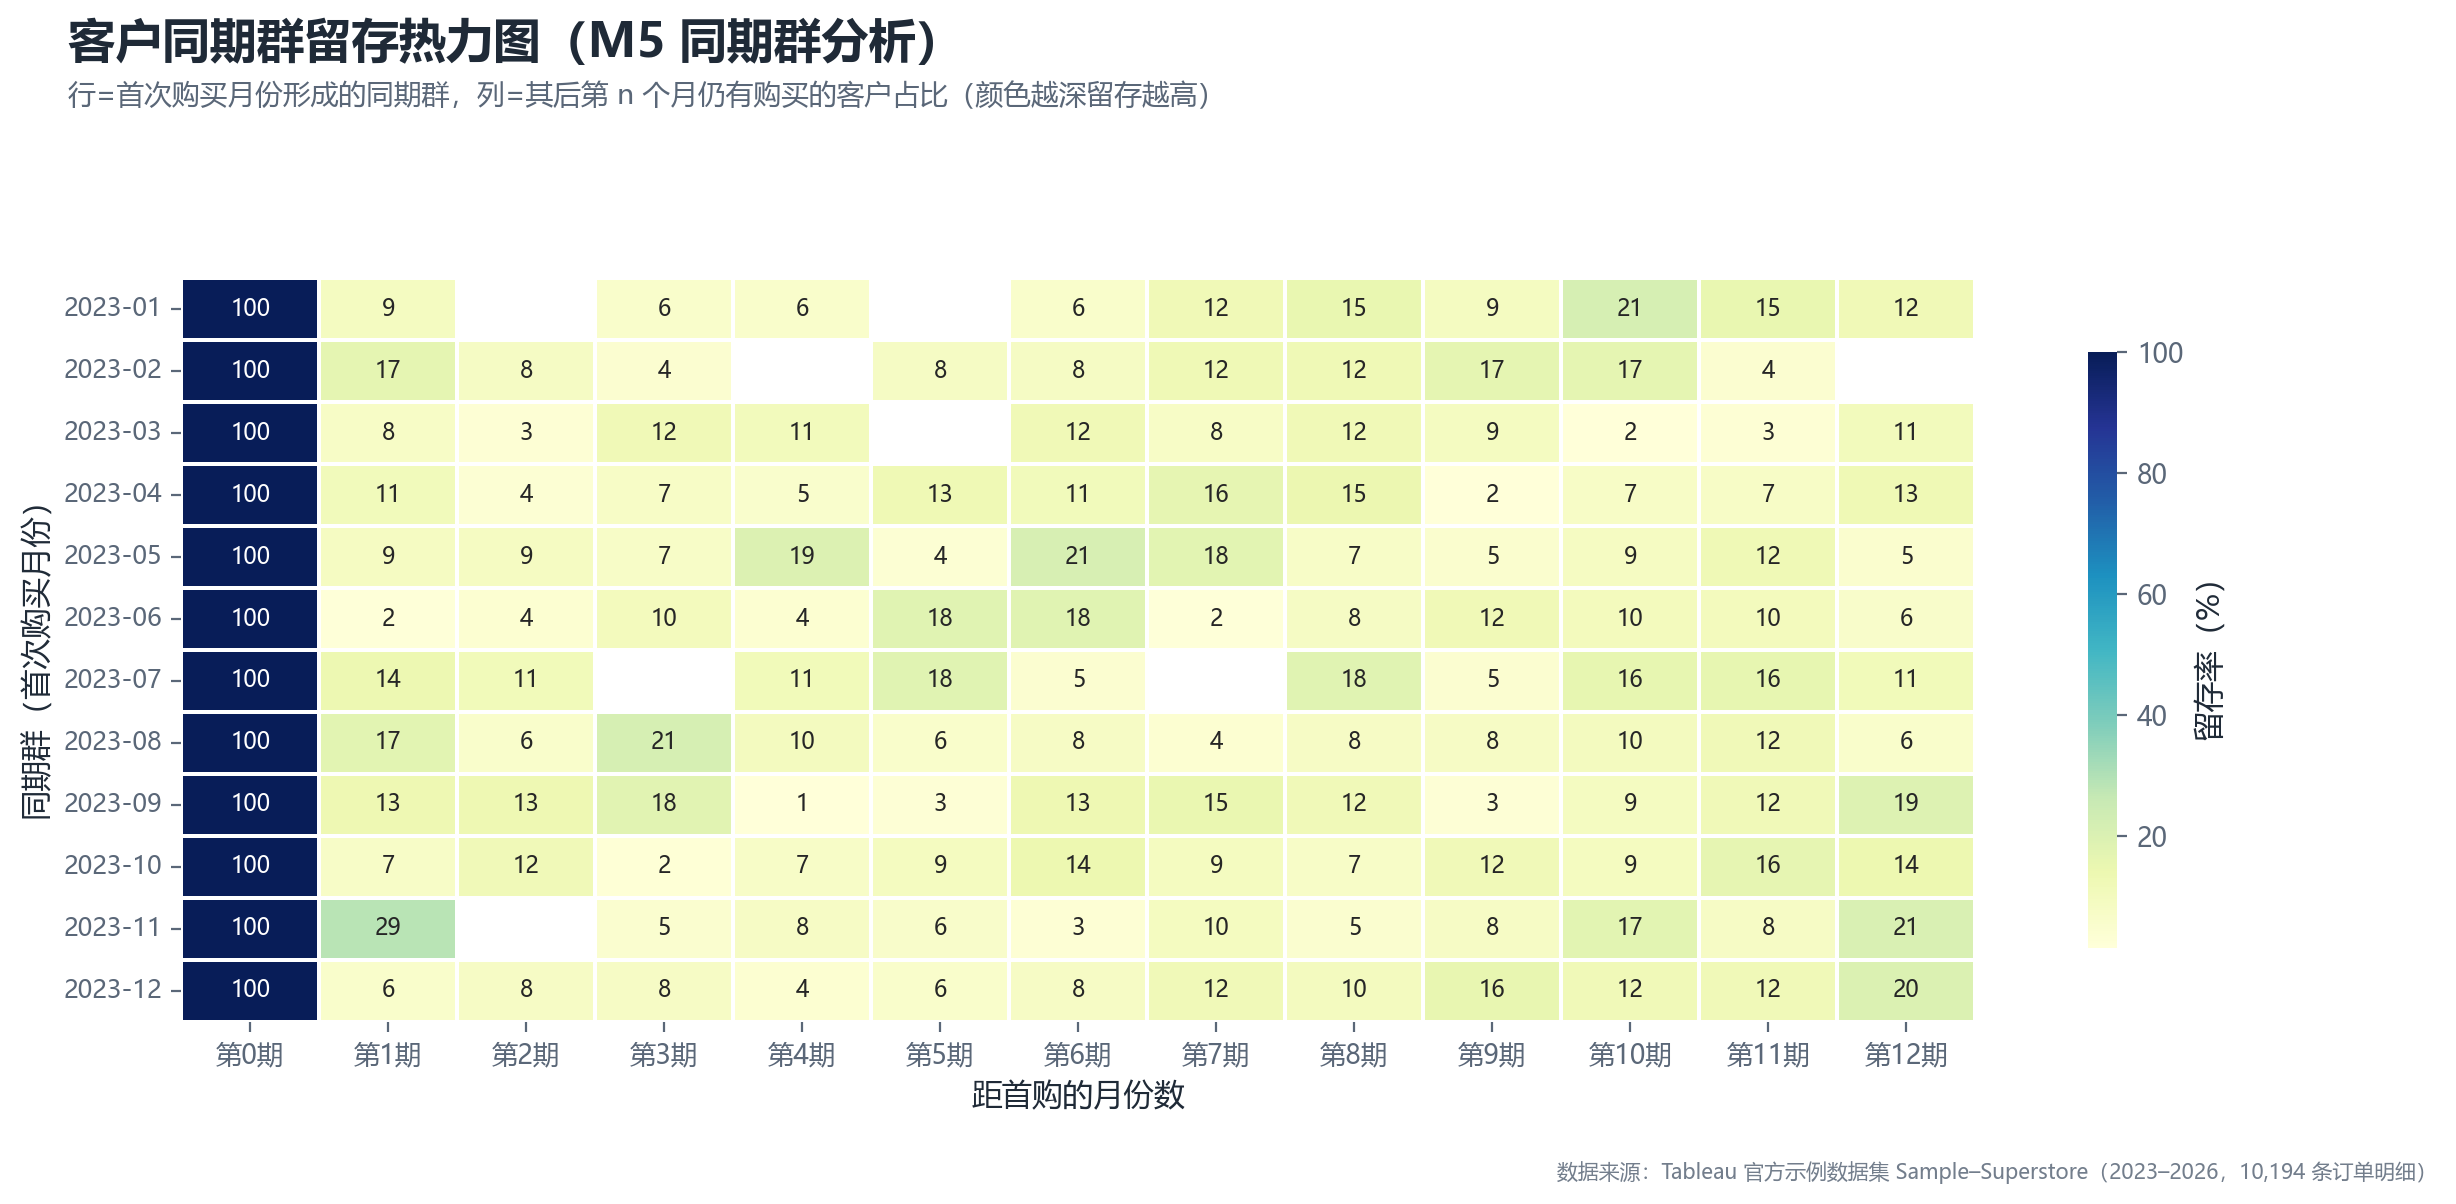

In [6]:
from IPython.display import Image, display
for f in ["fig16_帕累托ABC.png","fig17_RFM八分类.png","fig20_波士顿矩阵.png",
          "fig21_预测置信区间.png","fig19_同期群留存.png"]:
    display(Image(filename=str(ROOT/"outputs"/"figures"/f), width=780))

## 3. 交互式大屏

技术：ECharts（Python 端组织数据与配置，输出单文件 HTML，ECharts 库随项目本地化，**双击即可离线打开**）。

组件清单（≥6 项）：

1. 5 个 KPI 卡（销售额/利润/毛利率/订单数/退货率，含同比）
2. 月度趋势（柱+同比线）
3. 品类结构环（可点击下钻）
4. 大区表现（柱+毛利率，可点击下钻）
5. 子类帕累托
6. RFM 八分类散点
7. 同期群留存热力图
8. 预测 + 95% 置信区间
9. 折扣—毛利弹性
10. 子类明细表
11. 三个筛选器（年份/大区/品类）+ 重置

联动机制：筛选器变更 → 重算全部 KPI 与图表；点击环形图/柱形图 → 写入筛选条件并全屏联动。

In [7]:
dash = load_step("step05", "05_dashboard.py")
out = dash.run()
print(out)

[05] 构建暗色交互大屏


      [√] 组件：5 KPI + 8 图表 + 1 明细表 + 3 筛选器
      [√] 数据点：主表 573 行、子类 272 行、RFM 804 点
      [√] 已生成 G:\ThinkPad\Documents\jupyter_wenjian\商业数据分析\数据分析大作业\dashboard\商业分析大屏.html（238 KB）
G:\ThinkPad\Documents\jupyter_wenjian\商业数据分析\数据分析大作业\dashboard\商业分析大屏.html


In [8]:
from IPython.display import HTML
HTML('<p>大屏文件：<b>dashboard/商业分析大屏.html</b>（双击用浏览器打开，支持筛选联动与下钻）</p>')

## 4. 图表索引

24 张图的完整清单（文件名、对应模板/模型、正文图号）见 `README.md` 的“图表索引”表与 `docs/图表索引.md`。

In [9]:
import os
files = sorted(os.listdir(ROOT/"outputs"/"figures"))
print(f"共 {len(files)} 张图：")
for f in files: print(" ", f)

共 26 张图：
  fig01_渐变柱形图.png
  fig02_带均值柱形图.png
  fig03_渐变圆角柱形图.png
  fig04_标注柱形图.png
  fig05_层叠柱形图.png
  fig06_蝴蝶图.png
  fig07_对比柱形图.png
  fig08_甘特图.png
  fig09_平滑折线图.png
  fig10_菱形走势图.png
  fig11_对比折线图.png
  fig12_单值圆环图.png
  fig13_水球图.png
  fig14_玫瑰图.png
  fig15_月度趋势与同比.png
  fig16_帕累托ABC.png
  fig17_RFM八分类.png
  fig18_KMeans客群.png
  fig19_同期群留存.png
  fig20_波士顿矩阵.png
  fig21_预测置信区间.png
  fig22_关联规则.png
  fig23_履约漏斗.png
  fig24_折扣毛利弹性.png
  fig25_大屏布局示意图.png
  fig26_大屏运行截图.png
